In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = "../data/raw/sample_walking.mp4"

cap = cv2.VideoCapture(video_path)

print("Video opened:", cap.isOpened())

Video opened: True


In [2]:
ret, frame = cap.read()

print("Frame read successfully:", ret)
print("Frame type:", type(frame))
print("Frame shape:", frame.shape if ret else None)

Frame read successfully: True
Frame type: <class 'numpy.ndarray'>
Frame shape: (1920, 1080, 3)


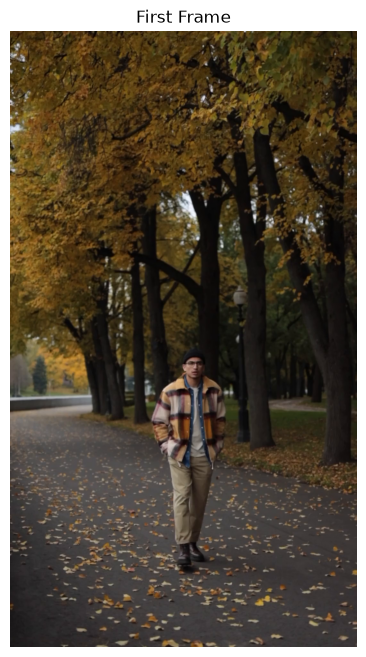

In [3]:
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("First Frame")
plt.show()

In [4]:
cap = cv2.VideoCapture(video_path)

for i in range(5):
    ret, frame = cap.read()

    if not ret:
        print(f"Couldn't read frame {i}")
        break

    print(f"Frame {i}: shape = {frame.shape}")


cap.release()

Frame 0: shape = (1920, 1080, 3)
Frame 1: shape = (1920, 1080, 3)
Frame 2: shape = (1920, 1080, 3)
Frame 3: shape = (1920, 1080, 3)
Frame 4: shape = (1920, 1080, 3)


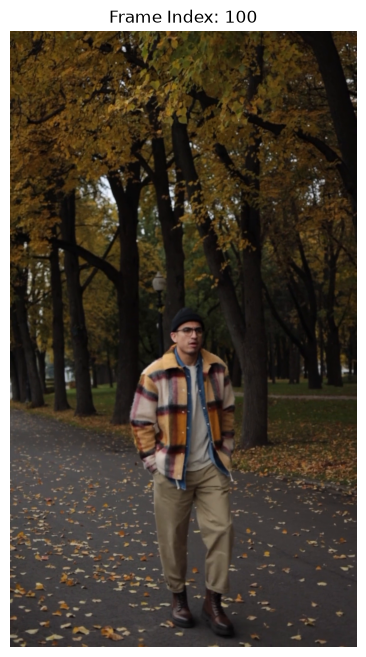

In [5]:
cap = cv2.VideoCapture(video_path)

frame_index = 100
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 8))
    plt.imshow(frame_rgb)
    plt.title(f"Frame Index: {frame_index}")
    plt.axis("off")
    plt.show()
else:
    print("Failed to read the selected frame.")

cap.release()

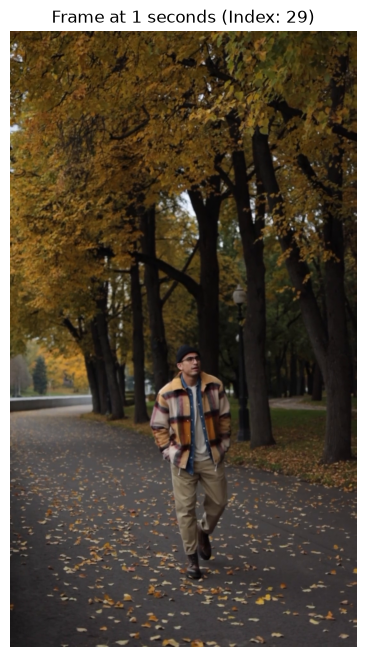

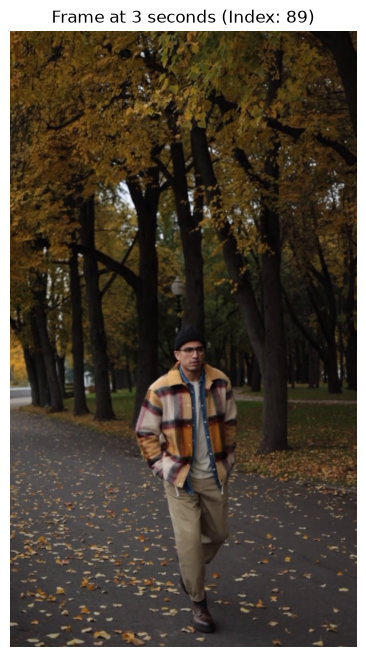

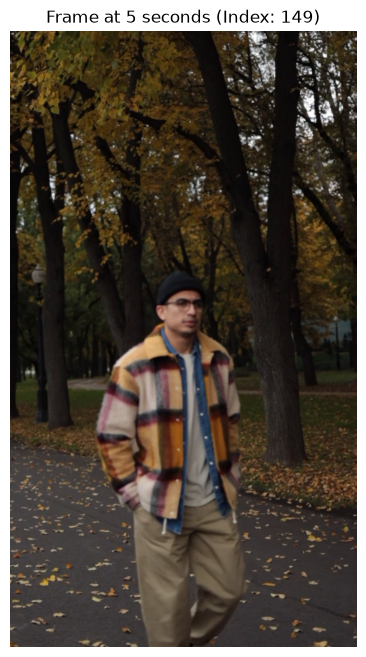

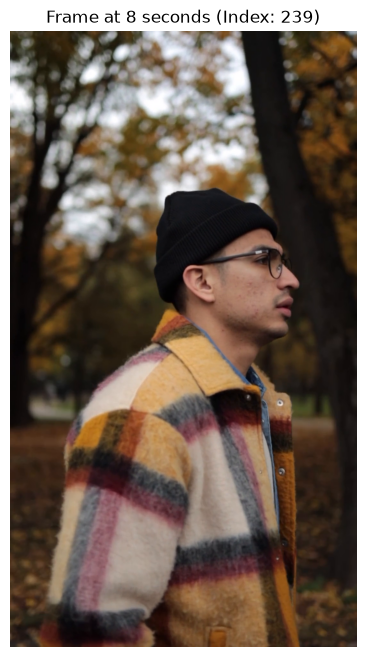

In [6]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

times = [1, 3, 5, 8]

for time in times:
    frame_index = int(time * fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(6, 8))
        plt.imshow(frame_rgb)
        plt.title(f"Frame at {time} seconds (Index: {frame_index})")
        plt.axis("off")
        plt.show()
    else:
        print(f"Failed to read frame at {time} seconds.")

cap.release()

In [7]:
from pathlib import Path

output_dir = Path("../data/interim/extracted_frames")
output_dir.mkdir(parents=True, exist_ok=True)

In [8]:
cap = cv2.VideoCapture(video_path)

video_fps = cap.get(cv2.CAP_PROP_FPS)

times = [1, 3, 5, 8]

for time in times:
    frame_index = int(time * video_fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

    ret, frame = cap.read()

    if ret:
        output_path = output_dir / f"frame_{time:03d}s.jpg"
        cv2.imwrite(str(output_path), frame)
        print(f"Saved frame at {time} seconds to {output_path}")
    else:
        print(f"Failed to read frame at {time} seconds.")

Saved frame at 1 seconds to ../data/interim/extracted_frames/frame_001s.jpg
Saved frame at 3 seconds to ../data/interim/extracted_frames/frame_003s.jpg
Saved frame at 5 seconds to ../data/interim/extracted_frames/frame_005s.jpg
Saved frame at 8 seconds to ../data/interim/extracted_frames/frame_008s.jpg


In [9]:
cap = cv2.VideoCapture(video_path)

frame_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break
    
    frame_count += 1


print("Frames successfully read:", frame_count)
print(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

Frames successfully read: 405
405.0


In [10]:
cap = cv2.VideoCapture(video_path)

sampling_interval_seconds = 1

frame_interval = int(sampling_interval_seconds * cap.get(cv2.CAP_PROP_FPS))

frame_count = 0
frame_index = 0

output_dir = Path("../data/interim/extracted_frames")

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % frame_interval == 0:
        output_path = output_dir / f"frame_{frame_index:04d}.jpg"
        success = cv2.imwrite(str(output_path), frame)
        if success:        
            print(f"Saved frame {frame_index} to {output_path}")
            frame_index += 1

    frame_count += 1

cap.release()

Saved frame 0 to ../data/interim/extracted_frames/frame_0000.jpg
Saved frame 1 to ../data/interim/extracted_frames/frame_0001.jpg
Saved frame 2 to ../data/interim/extracted_frames/frame_0002.jpg
Saved frame 3 to ../data/interim/extracted_frames/frame_0003.jpg
Saved frame 4 to ../data/interim/extracted_frames/frame_0004.jpg
Saved frame 5 to ../data/interim/extracted_frames/frame_0005.jpg
Saved frame 6 to ../data/interim/extracted_frames/frame_0006.jpg
Saved frame 7 to ../data/interim/extracted_frames/frame_0007.jpg
Saved frame 8 to ../data/interim/extracted_frames/frame_0008.jpg
Saved frame 9 to ../data/interim/extracted_frames/frame_0009.jpg
Saved frame 10 to ../data/interim/extracted_frames/frame_0010.jpg
Saved frame 11 to ../data/interim/extracted_frames/frame_0011.jpg
Saved frame 12 to ../data/interim/extracted_frames/frame_0012.jpg
Saved frame 13 to ../data/interim/extracted_frames/frame_0013.jpg


In [11]:
image_path = output_dir / "frame_0000.jpg"

image = cv2.imread(str(image_path))

print("Original shape:", image.shape)

Original shape: (1920, 1080, 3)


In [12]:
resized = cv2.resize(image, (540, 960))

print("Resized shape:", resized.shape)

Resized shape: (960, 540, 3)


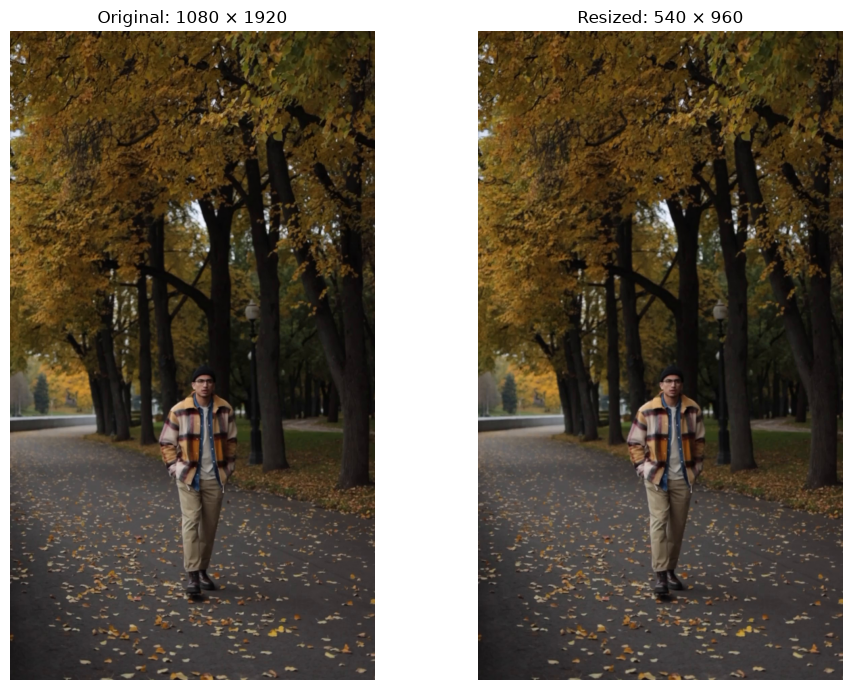

In [13]:
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 7))

axes[0].imshow(original_rgb)
axes[0].set_title(f"Original: {image.shape[1]} × {image.shape[0]}")
axes[0].axis("off")

axes[1].imshow(resized_rgb)
axes[1].set_title(f"Resized: {resized.shape[1]} × {resized.shape[0]}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [14]:
output_video_path = Path("../data/processed/resized_walking.mp4")
output_video_path.parent.mkdir

<bound method Path.mkdir of PosixPath('../data/processed')>

In [15]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise IOError(f"Cannot open video file: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = 540
height = 960

frame_size = (width, height)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

writer = cv2.VideoWriter(
    str(output_video_path),
    fourcc,
    fps,
    frame_size
)

processed_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    resized_frame = cv2.resize(frame, frame_size)
    writer.write(resized_frame)
    processed_count += 1

writer.release()
cap.release()

print("Processed frames:", processed_count)
print("Output video saved to:", output_video_path)

Processed frames: 405
Output video saved to: ../data/processed/resized_walking.mp4


Output FPS: 29.97
Output frame count: 405.0
Output width: 540.0
Output height: 960.0


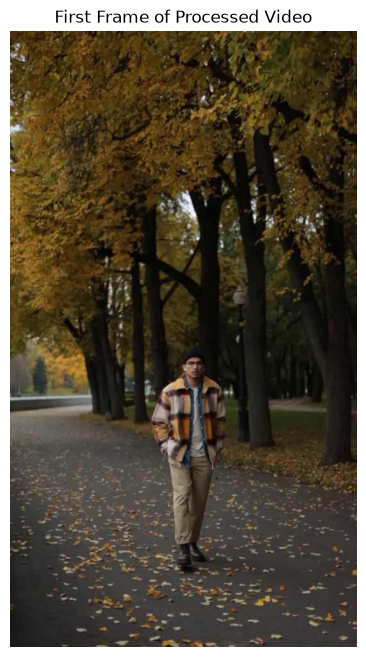

In [16]:
output_cap = cv2.VideoCapture(str(output_video_path))

if not output_cap.isOpened():
    raise RuntimeError("Could not reopen output video.")

print("Output FPS:", output_cap.get(cv2.CAP_PROP_FPS))
print("Output frame count:", output_cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("Output width:", output_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
print("Output height:", output_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

ret, output_frame = output_cap.read()

if ret:
    output_rgb = cv2.cvtColor(output_frame, cv2.COLOR_BGR2RGB)

    import matplotlib.pyplot as plt

    plt.figure(figsize=(5, 8))
    plt.imshow(output_rgb)
    plt.title("First Frame of Processed Video")
    plt.axis("off")
    plt.show()

output_cap.release()

In [17]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the first frame of the video.")

print("Frame shape:", frame.shape)

Frame shape: (1920, 1080, 3)


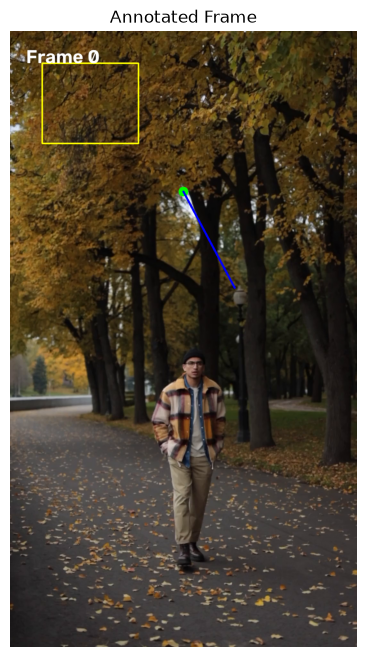

In [18]:
annotated_frame = frame.copy()

cv2.circle(
    annotated_frame,
    center=(540, 500),
    radius=15,
    color=(0, 255, 0),
    thickness=-1
)

cv2.line(
    annotated_frame,
    pt1=(540, 500),
    pt2=(700, 800),
    color=(255, 0, 0),
    thickness=5
)

cv2.rectangle(
    annotated_frame,
    pt1=(100, 100),
    pt2=(400, 350),
    color=(0, 255, 255),
    thickness=4
)

cv2.putText(
    annotated_frame,
    text="Frame 0",
    org=(50, 100),
    fontFace=cv2.FONT_HERSHEY_SIMPLEX,
    fontScale=2,
    color=(255, 255, 255),
    thickness=3,
    lineType=cv2.LINE_AA
)

annotated_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(annotated_rgb)
plt.title("Annotated Frame")
plt.axis("off")
plt.show()

In [19]:
output_video_path = Path("../data/processed/annotated_walking.mp4")

output_video_path.parent.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_size = (width, height)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

writer = cv2.VideoWriter(
    str(output_video_path),
    fourcc,
    fps,
    frame_size
)

center_x = width // 2
center_y = height // 2

while True:
    ret, frame = cap.read()

    if not ret:
        break

    cv2.circle(
        frame,
        center=(center_x, center_y),
        radius=15,
        color=(0, 255, 0),
        thickness=-1
    )

    cv2.line(
        frame,
        pt1=(center_x, center_y),
        pt2=(center_x + 160, center_y + 300),
        color=(255, 0, 0),
        thickness=5
    )

    cv2.rectangle(
        frame,
        pt1=(100, 100),
        pt2=(400, 350),
        color=(0, 255, 255),
        thickness=4
    )

    cv2.putText(
        frame,
        text=f"Frame {int(cap.get(cv2.CAP_PROP_POS_FRAMES))}",
        org=(50, 100),
        fontFace=cv2.FONT_HERSHEY_SIMPLEX,
        fontScale=2,
        color=(255, 255, 255),
        thickness=3,
        lineType=cv2.LINE_AA
    )

    writer.write(frame)

writer.release()
cap.release()

Annotated frame shape: (1920, 1080, 3)


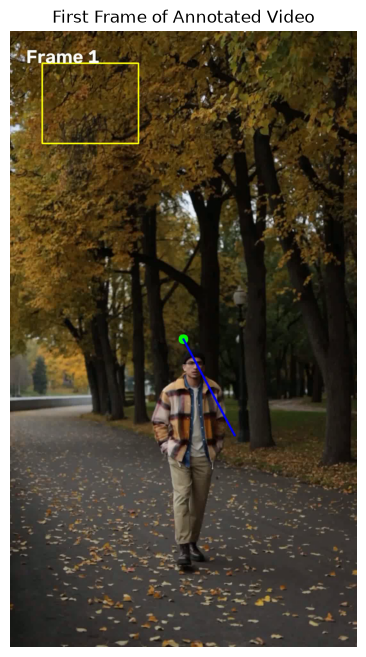

In [20]:
cap = cv2.VideoCapture(str(output_video_path))

ret, annotated_frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the first frame of the annotated video.")

print("Annotated frame shape:", annotated_frame.shape)

annotated_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(annotated_rgb)
plt.title("First Frame of Annotated Video")
plt.axis("off")
plt.show()

In [21]:
def get_video_info(video_path):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise IOError(f"Cannot open video file: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    cap.release()

    return {
        "fps": fps,
        "frame_count": frame_count,
        "width": width,
        "height": height
    }

In [22]:
info = get_video_info(video_path)

print("Video Information:", info)

Video Information: {'fps': 29.97002997002997, 'frame_count': 405, 'width': 1080, 'height': 1920}


In [23]:
def process_video(input_path, output_path):
    cap = None
    writer = None
    processed_count = 0
    try:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        
        cap = cv2.VideoCapture(input_path)

        if not cap.isOpened():
            raise IOError(f"Cannot open video file: {input_path}")

        writer = cv2.VideoWriter(
            str(output_path),
            cv2.VideoWriter_fourcc(*'mp4v'),
            cap.get(cv2.CAP_PROP_FPS),
            (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
        )

        if not writer.isOpened():
            raise IOError(f"Cannot open video writer for file: {output_path}")

        frame_index = 0
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            cv2.putText(
                frame,
                text=f"Frame {frame_index}",
                org=(50, 100),
                fontFace=cv2.FONT_HERSHEY_SIMPLEX,
                fontScale=2,
                color=(255, 255, 255),
                thickness=3,
                lineType=cv2.LINE_AA
            )

            writer.write(frame)
            frame_index += 1
            processed_count += 1
    finally:
        if writer is not None:
            writer.release()
        if cap is not None:
            cap.release()
    return processed_count


In [24]:
processed_frames = process_video(
    video_path,
    "../data/processed/annotated_walking_v2.mp4"
)

print("Total processed frames:", processed_frames)

Total processed frames: 405


In [25]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the video frame")

print("Image shape:", frame.shape)
print("Data type:", frame.dtype)
print("Minimum pixel value:", frame.min())
print("Maximum pixel value:", frame.max())

Image shape: (1920, 1080, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [26]:
# Select one pixel
y, x = 500, 300

pixel_bgr = frame[y, x]

print("Pixel coordinates (x, y):", (x, y))
print("Pixel value in BGR:", pixel_bgr)
print("Pixel data type:", pixel_bgr.dtype)

Pixel coordinates (x, y): (300, 500)
Pixel value in BGR: [19 52 74]
Pixel data type: uint8


In [27]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the first frame of the video.")

cropped = frame[400:1200, 200:800]

print("Original shape:", frame.shape)
print("Cropped shape:", cropped.shape)

Original shape: (1920, 1080, 3)
Cropped shape: (800, 600, 3)


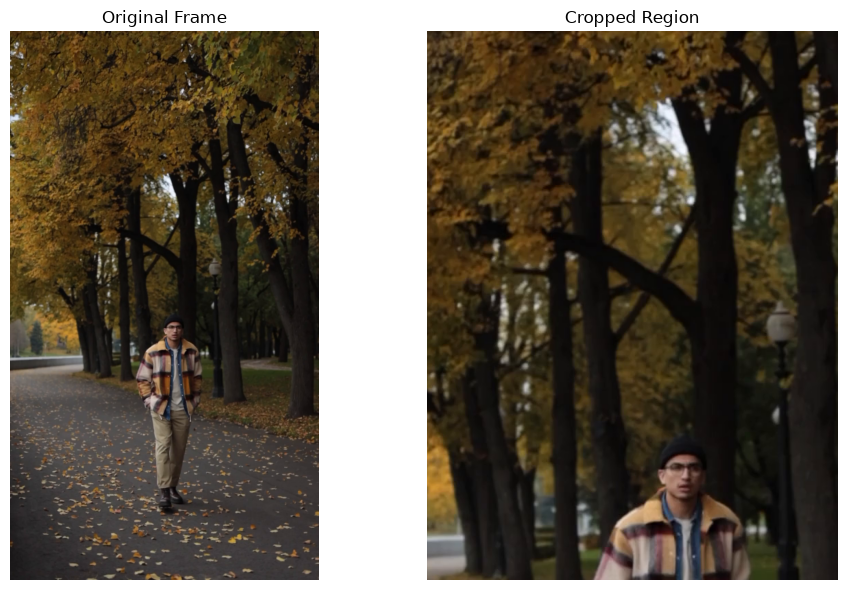

In [28]:
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
cropped_rgb = cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(frame_rgb)
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cropped_rgb)
plt.title("Cropped Region")
plt.axis("off")

plt.tight_layout()
plt.show()

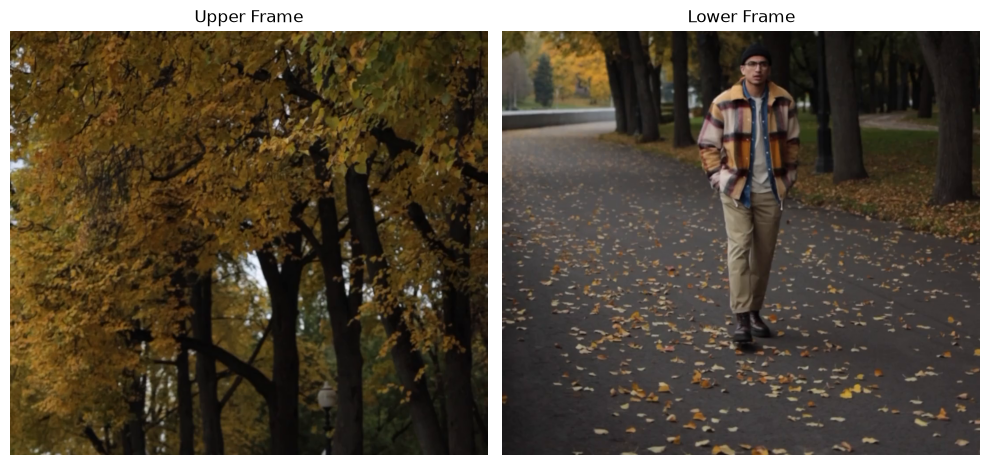

In [29]:
half_height = frame.shape[0] // 2
half_width = frame.shape[1] // 2

upper_frame = frame[:half_height, :]
lower_frame = frame[half_height:, :]

upper_rgb = cv2.cvtColor(upper_frame, cv2.COLOR_BGR2RGB)
lower_rgb = cv2.cvtColor(lower_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(upper_rgb)
plt.title("Upper Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lower_rgb)
plt.title("Lower Frame")
plt.axis("off")

plt.tight_layout()
plt.show()

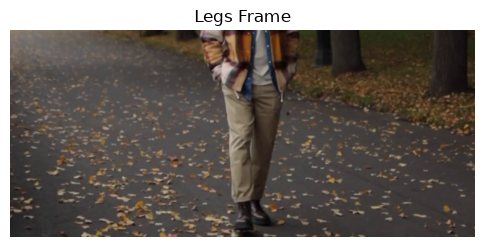

In [30]:
legs_frame = frame[int(2.5 * half_height // 2): int(3.5 * half_height // 2), :]

legs_rgb = cv2.cvtColor(legs_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(legs_rgb)
plt.title("Legs Frame")
plt.axis("off")
plt.show()

In [31]:
target_size = (256, 256)

resized_frame = cv2.resize(frame, target_size)

print("Original shape:", frame.shape)
print("Resized shape:", resized_frame.shape)

Original shape: (1920, 1080, 3)
Resized shape: (256, 256, 3)


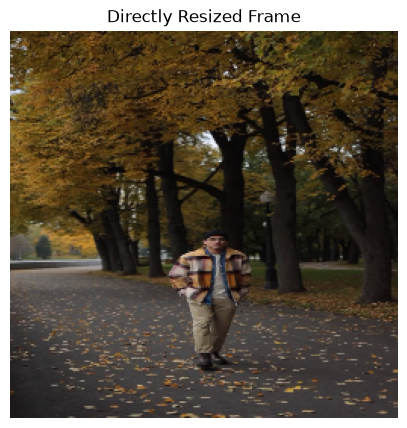

In [32]:
resized_rgb = cv2.cvtColor(
    resized_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 7))
plt.imshow(resized_rgb)
plt.title("Directly Resized Frame")
plt.axis("off")
plt.show()

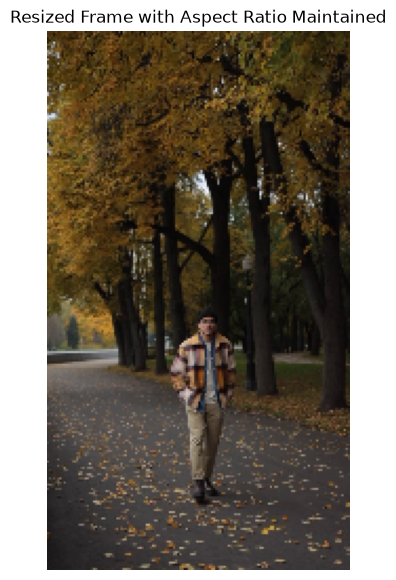

Resized shape with aspect ratio maintained: (256, 144, 3)
Scaled factor: 0.13333333333333333


In [33]:
target_width = 256
target_hight = 256

original_height, original_width = frame.shape[:2]

scale = min(target_width / original_width, target_hight / original_height)

new_width = int(original_width * scale)
new_height = int(original_height * scale)

resized_frame = cv2.resize(frame, (new_width, new_height))

plt.figure(figsize=(5, 7))
plt.imshow(cv2.cvtColor(resized_frame, cv2.COLOR_BGR2RGB))
plt.title("Resized Frame with Aspect Ratio Maintained")
plt.axis("off")
plt.show()
print("Resized shape with aspect ratio maintained:", resized_frame.shape)
print("Scaled factor:", scale)

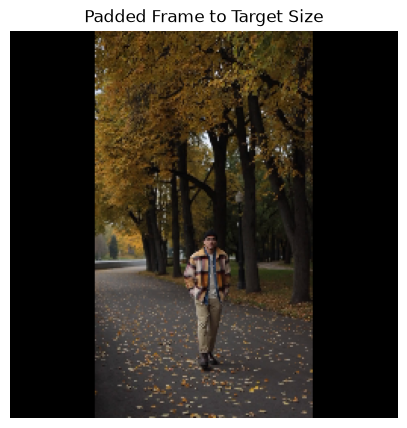

Final padded shape: (256, 256, 3)


In [34]:
pad_x = (target_width - new_width) // 2
pad_y = (target_hight - new_height) // 2

new_img = np.zeros((target_hight, target_width, 3), dtype=np.uint8)

new_img[pad_y:pad_y + new_height, pad_x:pad_x + new_width] = resized_frame

plt.figure(figsize=(5, 7))
plt.imshow(cv2.cvtColor(new_img, cv2.COLOR_BGR2RGB))
plt.title("Padded Frame to Target Size")
plt.axis("off")
plt.show()
print("Final padded shape:", new_img.shape)

In [35]:
x_model = 100
y_model = 180

pad_x = 56
pad_y = 0

scale = 0.133333

x_real = (x_model - pad_x) / scale
y_real = (y_model - pad_y) / scale

print("Model coordinates (x_model, y_model):", (int(x_model), int(y_model)))
print("Real-world coordinates (x_real, y_real):", (int(x_real), int(y_real)))

Model coordinates (x_model, y_model): (100, 180)
Real-world coordinates (x_real, y_real): (330, 1350)


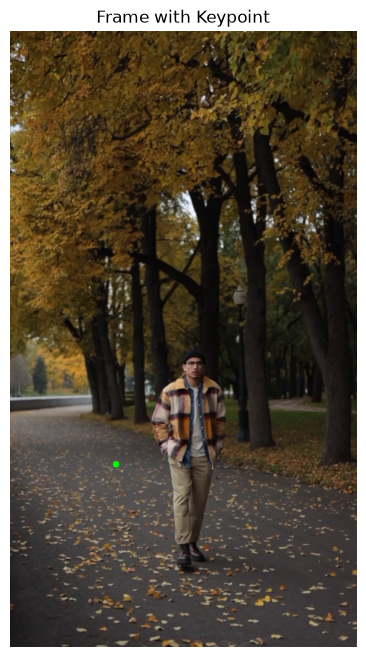

In [37]:
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()

frame_with_keypoints = frame.copy()
cap.release()

cv2.circle(
    frame_with_keypoints,
    center=(int(x_real), int(y_real)),
    radius=10,
    color=(0, 255, 0),
    thickness=-1
)

plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(frame_with_keypoints, cv2.COLOR_BGR2RGB))
plt.title("Frame with Keypoint")
plt.axis("off")
plt.show()